Epoch [10/30], 总Loss: 0.021143, MSE: 0.019559, 物理惩罚: 0.003169
Epoch [20/30], 总Loss: 0.022704, MSE: 0.021038, 物理惩罚: 0.003333
Epoch [30/30], 总Loss: 0.021545, MSE: 0.019622, 物理惩罚: 0.003845


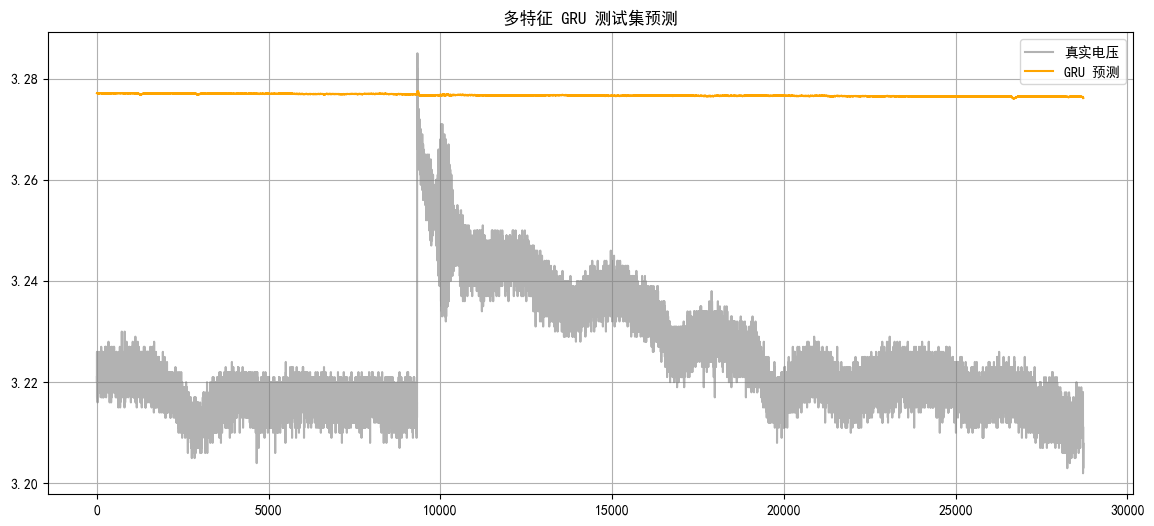

🔥 多特征 GRU 测试集 RMSE: 0.053224 V


In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import math
from sklearn.metrics import mean_squared_error

# 解决中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 读数据与特征工程 =================
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv'
df = pd.read_csv(file_path)#（这里FC1是合并过后的表格，不需要考虑兼容性，因为这已经是转换过的了）

# 【关键升级】喂给它 4 个特征：时间、电压、出口氢温、空气湿度
# 确保这些列名在 df.columns 里存在，如果没有，你可以把温度换成 ToutWAT (°C) 等
features = ['Time (h)', 'Utot (V)', 'ToutH2 (°C)', 'HrAIRFC (%)']
data = df[features].values

split_idx = int(len(data) * 0.8)
train_data = data[:split_idx]
test_data = data[split_idx:]

# 防泄漏归一化
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# ================= 2. 滑动窗口 =================
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i : i + seq_length])
        # 注意：y 取的是下标为 1 的列（也就是 Utot），因为我们要预测电压
        ys.append(data[i + seq_length, 1])
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 50
X_train_lstm, y_train_lstm = create_sequences(train_scaled, SEQ_LENGTH)
X_test_lstm, y_test_lstm = create_sequences(test_scaled, SEQ_LENGTH)

X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_lstm)
y_test_tensor = torch.FloatTensor(y_test_lstm).unsqueeze(1)

# ================= 3. 定义 GRU 模型 =================
class VoltageGRU(nn.Module):
    # 注意：input_size=4 了！因为有四个特征
    def __init__(self, input_size=4, hidden_size=48, num_layers=1, output_size=1):
        super(VoltageGRU, self).__init__()
        # 只改了这一行：把 LSTM 换成了 GRU
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

model = VoltageGRU()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=512, shuffle=True)

import torch
import torch.nn as nn

# ================= 物理约束模块 =================
class PhysicsInformedLoss(nn.Module):
    def __init__(self, lambda_penalty=0.1):
        super(PhysicsInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_penalty = lambda_penalty # 惩罚力度

    def forward(self, y_pred, y_true):
        # 1. 普通的预测误差
        mse_loss = self.mse(y_pred, y_true)

        # 2. 物理惩罚：相邻预测点之间的差值
        # y_pred 的形状是 (batch_size, 1)，我们没法直接看序列趋势
        # 为了演示，这里我们用一个小技巧：如果预测值比上一个真实值还大，就惩罚
        # （完整的单调性约束通常需要在自回归生成时按序列惩罚）

        # 简单版惩罚：预测出的电压趋势不应该剧烈向上突变
        # 因为我们已知电池在衰减，如果预测的下一个值显著高于当前值，就不符合物理规律
        # 这里我们用一个近似：惩罚相邻样本预测值的正向跳跃
        diff = y_pred[1:] - y_pred[:-1]
        # 如果 diff > 0（上升），relu 会保留它；如果下降，relu 会变成 0
        penalty = torch.mean(torch.relu(diff))

        total_loss = mse_loss + self.lambda_penalty * penalty
        return total_loss, mse_loss, penalty

# ================= 训练循环替换 =================
# 假设 model, train_loader, optimizer 已经定义好
criterion = PhysicsInformedLoss(lambda_penalty=0.5) # 你可以调整这个 0.5 试试

epochs = 30
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)

        # 注意：这里用我们自定义的物理 Loss
        loss, mse, penalty = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], 总Loss: {loss.item():.6f}, MSE: {mse.item():.6f}, 物理惩罚: {penalty.item():.6f}')

# ================= 5. 测试与反归一化 =================
model.eval()
with torch.no_grad():
    predictions = model(X_test_tensor)

# 多特征反归一化（核心难点，不要改错）
# 建一个假的 4 维矩阵，只把第 1 列（电压）换成预测值，其他填 0
dummy = np.zeros((len(predictions), 4))
dummy[:, 1] = predictions.numpy().flatten()
predictions_real = scaler.inverse_transform(dummy)[:, 1]

# 对真实值也做同样处理
dummy_y = np.zeros((len(y_test_tensor), 4))
dummy_y[:, 1] = y_test_tensor.numpy().flatten()
y_test_real = scaler.inverse_transform(dummy_y)[:, 1]

# ================= 6. 画图与评估 =================
plt.figure(figsize=(14, 6))
plt.plot(y_test_real, label='真实电压', color='gray', alpha=0.6)
plt.plot(predictions_real, label='GRU 预测', color='orange')
plt.title('多特征 GRU 测试集预测')
plt.legend()
plt.grid(True)
plt.show()

rmse_gru = math.sqrt(mean_squared_error(y_test_real, predictions_real))
print(f"🔥 多特征 GRU 测试集 RMSE: {rmse_gru:.6f} V")

In [ ]:
import torch
import torch.nn as nn

# ================= 物理约束模块 =================
class PhysicsInformedLoss(nn.Module):
    def __init__(self, lambda_penalty=0.1):
        super(PhysicsInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_penalty = lambda_penalty # 惩罚力度

    def forward(self, y_pred, y_true):
        # 1. 普通的预测误差
        mse_loss = self.mse(y_pred, y_true)

        # 2. 物理惩罚：相邻预测点之间的差值
        # y_pred 的形状是 (batch_size, 1)，我们没法直接看序列趋势
        # 为了演示，这里我们用一个小技巧：如果预测值比上一个真实值还大，就惩罚
        # （完整的单调性约束通常需要在自回归生成时按序列惩罚）

        # 简单版惩罚：预测出的电压趋势不应该剧烈向上突变
        # 因为我们已知电池在衰减，如果预测的下一个值显著高于当前值，就不符合物理规律
        # 这里我们用一个近似：惩罚相邻样本预测值的正向跳跃
        diff = y_pred[1:] - y_pred[:-1]
        # 如果 diff > 0（上升），relu 会保留它；如果下降，relu 会变成 0
        penalty = torch.mean(torch.relu(diff))

        total_loss = mse_loss + self.lambda_penalty * penalty
        return total_loss, mse_loss, penalty

# ================= 训练循环替换 =================
# 假设 model, train_loader, optimizer 已经定义好
criterion = PhysicsInformedLoss(lambda_penalty=0.5) # 你可以调整这个 0.5 试试

epochs = 30
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)

        # 注意：这里用我们自定义的物理 Loss
        loss, mse, penalty = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], 总Loss: {loss.item():.6f}, MSE: {mse.item():.6f}, 物理惩罚: {penalty.item():.6f}')